---
# Part 1 — Data Preparation & Pipeline

## 1.1 Problem framing
| Item | Our choice |
|---|---|
| **Business problem** | A telecom company loses customers ("churn"). If we can predict who is about to leave, the company can offer them a discount or support before they go. |
| **Prediction target** | `Churn` — did the customer leave? (Yes = 1, No = 0) |
| **Task type** | Binary **classification** (two possible answers) |
| **Success metric** | **F1-score** (main) and **ROC-AUC**. We do **not** rely on accuracy because only ~27% of customers churn: a useless model that always says "No" would already be ~73% accurate. F1 rewards a model only if it actually finds the churners. |
| **Why this dataset** | 7,043 rows (> 1,000 required); mix of numeric (tenure, charges) and categorical (contract, payment method, services) features; real data problems to fix (missing values, class imbalance); good for clustering (customer segments) and fairness analysis (gender, senior citizens) in later parts; public, no privacy issues. |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed number so everyone gets the same results every time
print("Libraries loaded ✔")

Libraries loaded ✔


In [2]:
# Load the dataset
FILE = "Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

if os.path.exists(FILE):
    df = pd.read_csv(FILE)
else:
    df = pd.read_csv(URL)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Column info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
# Cleaning Data
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("Missing values per column (only columns that have some):")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values per column (only columns that have some):
TotalCharges    11
dtype: int64


In [6]:
# Customers with missing TotalCharges?
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


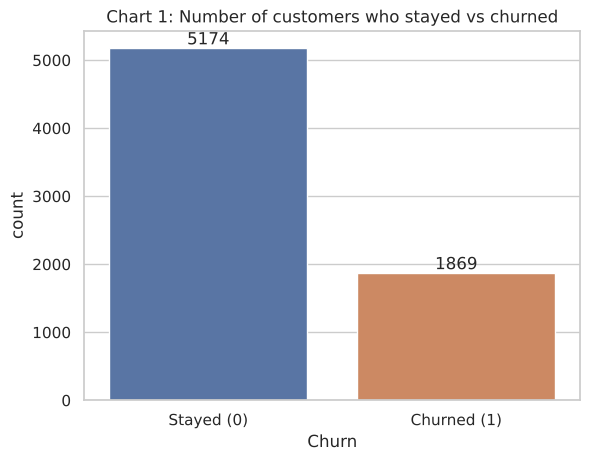

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [7]:
# Exploratory Data Analysis (EDA
# Chart 1
ax = sns.countplot(x="Churn", data=df, hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
ax.set_title("Chart 1: Number of customers who stayed vs churned")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

### Chart 2 — Churn rate by contract type

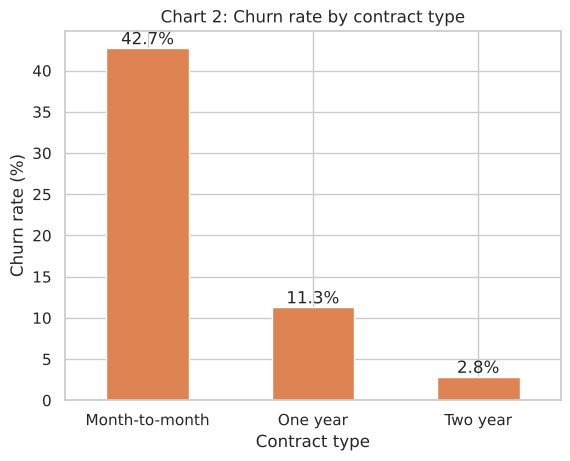

In [8]:
# Chart2
rate = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False) * 100
ax = rate.plot(kind="bar", color="#DD8452")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Contract type")
ax.set_title("Chart 2: Churn rate by contract type")
plt.xticks(rotation=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.show()

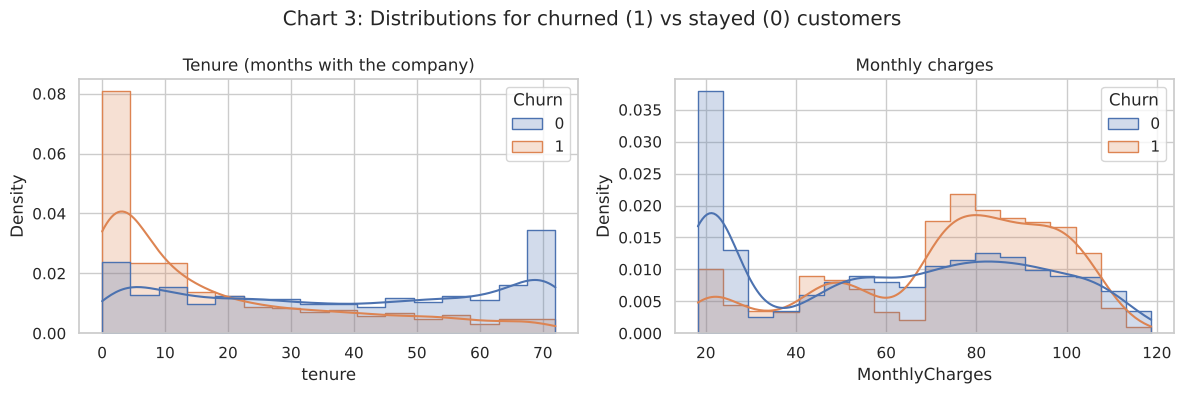

In [9]:
# Chart3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Tenure (months with the company)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_title("Monthly charges")
fig.suptitle("Chart 3: Distributions for churned (1) vs stayed (0) customers")
plt.tight_layout(); plt.show()

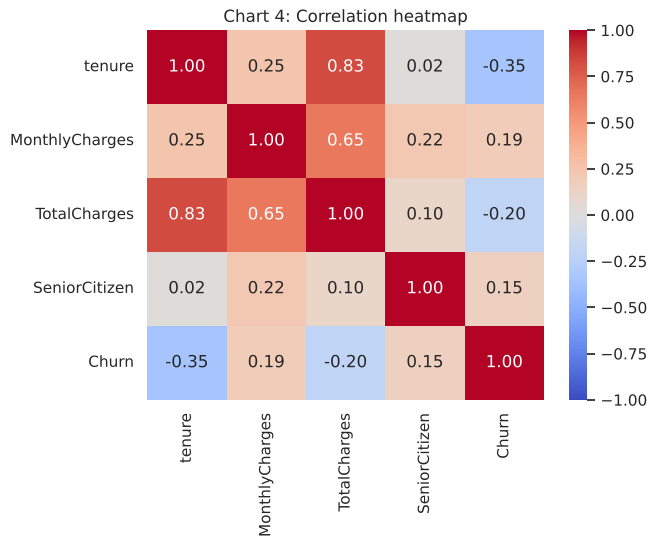

In [10]:
# Chart4
num_for_corr = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Chart 4: Correlation heatmap")
plt.show()

tenure          -> outliers: 0
MonthlyCharges  -> outliers: 0
TotalCharges    -> outliers: 0


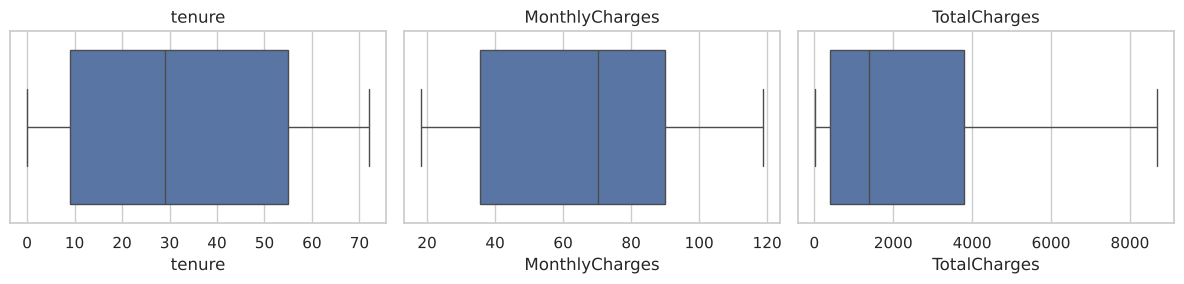

In [11]:
# Outlier Check:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:15s} -> outliers: {n_out}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=df[col], ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

In [12]:
# Data leakage testing:
X = df.drop(columns=["Churn"])   # features (inputs)
y = df["Churn"]                  # target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, " churn rate:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, " churn rate:", round(y_test.mean(), 3))

Training set: (5634, 19)  churn rate: 0.265
Test set:     (1409, 19)  churn rate: 0.265


In [13]:
# Feature Construction:
SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(data):
    data = data.copy()
    data["AvgMonthlySpend"] = data["TotalCharges"] / (data["tenure"] + 1)
    data["NumServices"] = (data[SERVICE_COLS] == "Yes").sum(axis=1)
    return data

feature_maker = FunctionTransformer(add_features)

# quick test on 3 rows
add_features(X_train.head(3))[["tenure", "TotalCharges", "AvgMonthlySpend", "NumServices"]]

,tenure,TotalCharges,AvgMonthlySpend,NumServices
3738,35,1701.65,47.268056,3
3151,15,1151.55,71.971875,2
4860,13,590.35,42.167857,3


In [14]:
# PreProcessing with ColumnsTransformer:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "NumServices", "SeniorCitizen"]
categorical_features = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                        "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                        "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                        "PaperlessBilling", "PaymentMethod"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

In [15]:
# The full leakage free pipeline:
model_pipeline = Pipeline([
    ("features", feature_maker),
    ("preprocess", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f51c1bc4b80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDicti

In [16]:
# Cross validation on the training set:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(model_pipeline, X_train, y_train, cv=cv, scoring=["f1", "roc_auc", "accuracy"])

print(f"CV F1      : {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}")
print(f"CV ROC-AUC : {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
print(f"CV Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

CV F1      : 0.634 ± 0.019
CV ROC-AUC : 0.849 ± 0.012
CV Accuracy: 0.756 ± 0.012


Test F1     : 0.617
Test ROC-AUC: 0.847

              precision    recall  f1-score   support

      Stayed       0.90      0.73      0.81      1035
     Churned       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



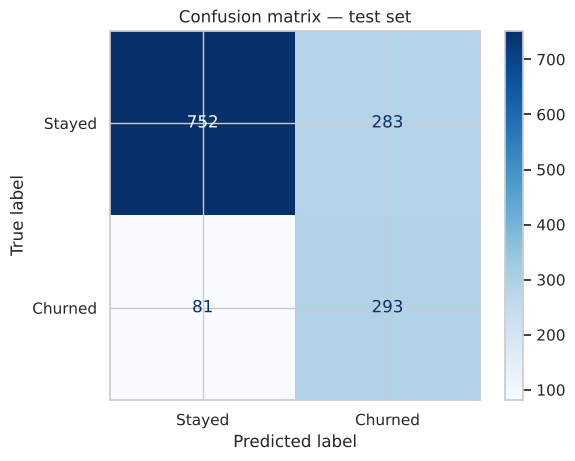

In [17]:
# Final Check on the test set:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print(f"Test F1     : {f1_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Confusion matrix — test set")
plt.show()

---
# Part 2 — Supervised Learning Baseline
Naive Bayes (probabilistic) vs. Decision Tree (tree-based) on the same leakage-free pipeline from Part 1.

In [18]:
# Imports for Part 2:
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import precision_score, recall_score, accuracy_score, RocCurveDisplay

In [19]:
# Models and pipelines:
# Naive Bayes needs a dense matrix, so the one-hot encoder outputs dense data here
dense_preprocessor = clone(preprocessor).set_params(cat__onehot__sparse_output=False)

def make_model_pipeline(model):
    return Pipeline([
        ("features", feature_maker),
        ("preprocess", clone(dense_preprocessor)),
        ("model", model),
    ])

models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Decision Tree (depth 5)": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                                       class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree (no limit)": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
pipelines = {name: make_model_pipeline(m) for name, m in models.items()}
list(pipelines)

['Gaussian Naive Bayes',
 'Bernoulli Naive Bayes',
 'Decision Tree (depth 5)',
 'Decision Tree (no limit)']

## 2.1 Hand-worked Gini split
Random sample of 20 training customers, split on **"Contract = Month-to-month?"**

Gini = 1 − (p<sub>stay</sub>² + p<sub>churn</sub>²)

| Group | Stayed (0) | Churned (1) | Total |
|---|---|---|---|
| Parent (all 20) | 15 | 5 | 20 |
| Month-to-month | 5 | 5 | 10 |
| One / Two year | 10 | 0 | 10 |

- Parent: 1 − (0.75² + 0.25²) = 1 − (0.5625 + 0.0625) = **0.375**
- Month-to-month: 1 − (0.5² + 0.5²) = **0.5**
- One / Two year: 1 − (1² + 0²) = **0** (pure)
- Weighted Gini after split: (10/20)(0.5) + (10/20)(0) = **0.25**
- **Gini gain = 0.375 − 0.25 = 0.125**
- Information gain (entropy): 0.811 − [0.5(1.0) + 0.5(0)] = **0.311**

Check in code below (with "gender = Male" as a weak split for comparison):

In [20]:
# Verify the hand calculation:
sample = X_train.assign(Churn=y_train).sample(20, random_state=2)

def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()

def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def split_quality(data, condition, name):
    left, right = data[condition], data[~condition]
    w_l, w_r = len(left) / len(data), len(right) / len(data)
    g_parent, e_parent = gini(data["Churn"]), entropy(data["Churn"])
    g_children = w_l * gini(left["Churn"]) + w_r * gini(right["Churn"])
    e_children = w_l * entropy(left["Churn"]) + w_r * entropy(right["Churn"])
    print(f"Split: {name}")
    print(f"  left: {len(left)} customers ({left['Churn'].sum()} churn) | right: {len(right)} customers ({right['Churn'].sum()} churn)")
    print(f"  Gini parent = {g_parent:.3f} | weighted Gini = {g_children:.3f} | Gini gain = {g_parent - g_children:.3f}")
    print(f"  Entropy parent = {e_parent:.3f} | weighted entropy = {e_children:.3f} | Information gain = {e_parent - e_children:.3f}")
    print()

split_quality(sample, sample["Contract"] == "Month-to-month", "Contract == Month-to-month")
split_quality(sample, sample["gender"] == "Male", "gender == Male")
sample[["Contract", "gender", "tenure", "MonthlyCharges", "Churn"]]

Split: Contract == Month-to-month
  left: 10 customers (5 churn) | right: 10 customers (0 churn)
  Gini parent = 0.375 | weighted Gini = 0.250 | Gini gain = 0.125
  Entropy parent = 0.811 | weighted entropy = 0.500 | Information gain = 0.311

Split: gender == Male
  left: 11 customers (3 churn) | right: 9 customers (2 churn)
  Gini parent = 0.375 | weighted Gini = 0.374 | Gini gain = 0.001
  Entropy parent = 0.811 | weighted entropy = 0.809 | Information gain = 0.002



,Contract,gender,tenure,MonthlyCharges,Churn
6715,Month-to-month,Female,11,89.20,0
1656,Month-to-month,Female,53,90.80,0
3520,Month-to-month,Female,16,19.60,0
1052,One year,Female,40,80.75,0
134,Month-to-month,Male,2,44.35,1
4228,Month-to-month,Male,1,68.50,1
1371,Month-to-month,Female,1,79.20,1
3018,Two year,Male,67,25.10,0
2624,Month-to-month,Male,17,66.70,0
1503,One year,Female,45,102.15,0


In [21]:
# Cross validation (5-fold stratified):
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, pipe in pipelines.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    row = {"Model": name}
    for m in scoring:
        row[m] = s[f"test_{m}"].mean()
    row["F1 std"] = s["test_f1"].std()
    row["Train F1"] = s["train_f1"].mean()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_results

,accuracy,precision,recall,f1,roc_auc,F1 std,Train F1
Model,,,,,,,
Gaussian Naive Bayes,0.696,0.461,0.847,0.597,0.820,0.009,0.596
Bernoulli Naive Bayes,0.726,0.491,0.807,0.610,0.820,0.012,0.611
Decision Tree (depth 5),0.742,0.510,0.773,0.614,0.829,0.008,0.643
Decision Tree (no limit),0.732,0.495,0.486,0.490,0.653,0.024,0.996


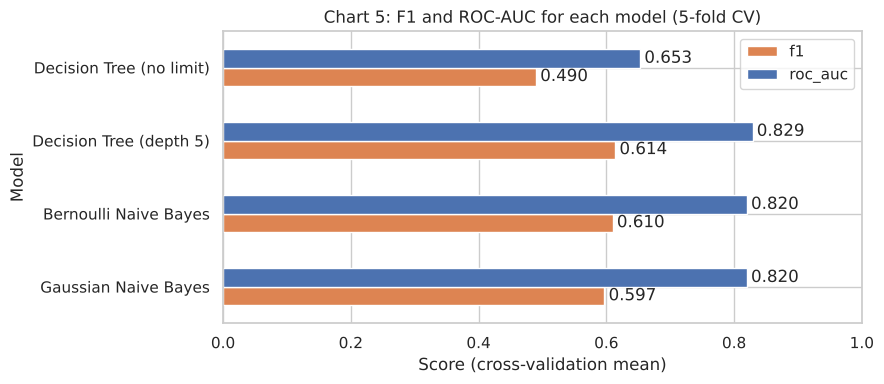

In [22]:
# Chart 5
ax = cv_results[["f1", "roc_auc"]].plot(kind="barh", figsize=(9, 4), color=["#DD8452", "#4C72B0"])
ax.set_xlim(0, 1); ax.set_xlabel("Score (cross-validation mean)")
ax.set_title("Chart 5: F1 and ROC-AUC for each model (5-fold CV)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3)
plt.tight_layout(); plt.show()

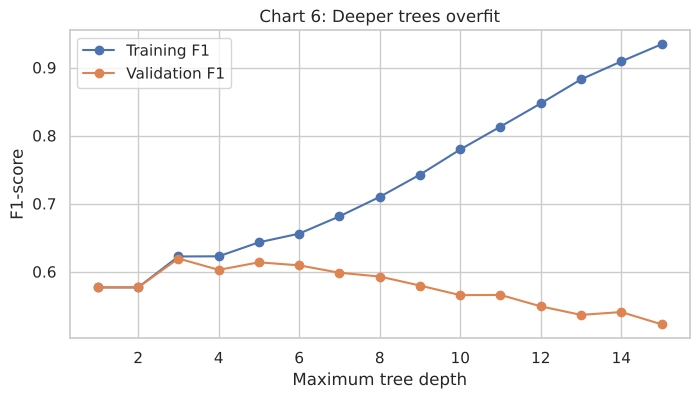

Best validation F1 = 0.619 at depth 3


In [23]:
# Chart 6 - tree depth vs overfitting:
depths = range(1, 16)
train_f1, val_f1 = [], []
for d in depths:
    pipe = make_model_pipeline(DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE))
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    train_f1.append(s["train_score"].mean()); val_f1.append(s["test_score"].mean())

plt.figure(figsize=(8, 4))
plt.plot(depths, train_f1, marker="o", label="Training F1")
plt.plot(depths, val_f1, marker="o", label="Validation F1")
plt.xlabel("Maximum tree depth"); plt.ylabel("F1-score")
plt.title("Chart 6: Deeper trees overfit")
plt.legend(); plt.show()

best_d = list(depths)[int(np.argmax(val_f1))]
print(f"Best validation F1 = {max(val_f1):.3f} at depth {best_d}")

In [24]:
# Final check on the test set:
test_rows = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    test_rows.append({"Model": name,
                      "accuracy": accuracy_score(y_test, pred),
                      "precision": precision_score(y_test, pred),
                      "recall": recall_score(y_test, pred),
                      "f1": f1_score(y_test, pred),
                      "roc_auc": roc_auc_score(y_test, prob)})
test_results = pd.DataFrame(test_rows).set_index("Model").round(3)
test_results

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Gaussian Naive Bayes,0.693,0.457,0.834,0.590,0.806
Bernoulli Naive Bayes,0.716,0.479,0.794,0.598,0.806
Decision Tree (depth 5),0.755,0.527,0.759,0.622,0.832
Decision Tree (no limit),0.739,0.508,0.487,0.497,0.659


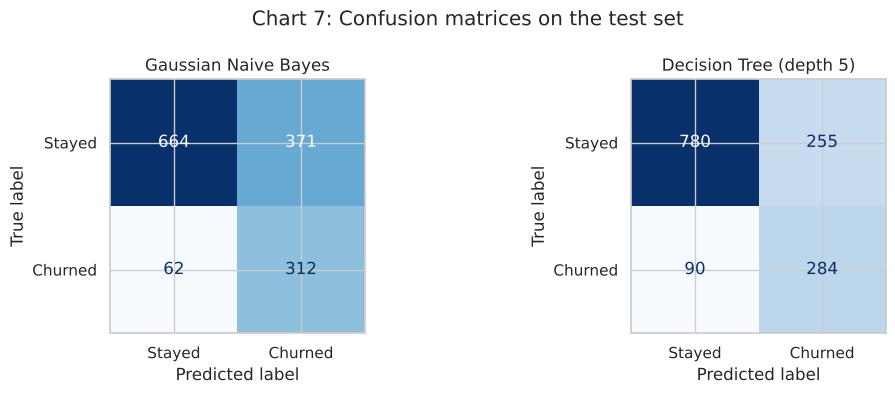

In [25]:
# Chart 7 - confusion matrices:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["Gaussian Naive Bayes", "Decision Tree (depth 5)"]):
    ConfusionMatrixDisplay.from_estimator(pipelines[name], X_test, y_test,
                                          display_labels=["Stayed", "Churned"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
fig.suptitle("Chart 7: Confusion matrices on the test set")
plt.tight_layout(); plt.show()

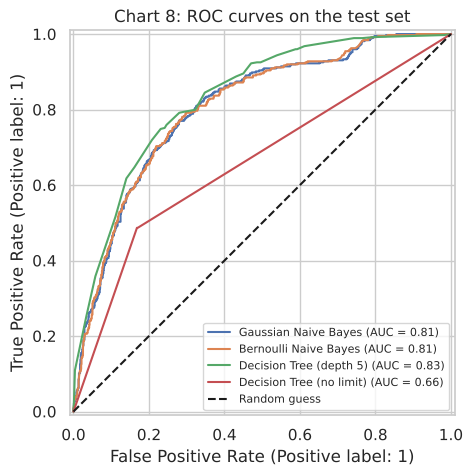

In [26]:
# Chart 8 - ROC curves:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("Chart 8: ROC curves on the test set")
ax.legend(loc="lower right", fontsize=8)
plt.show()

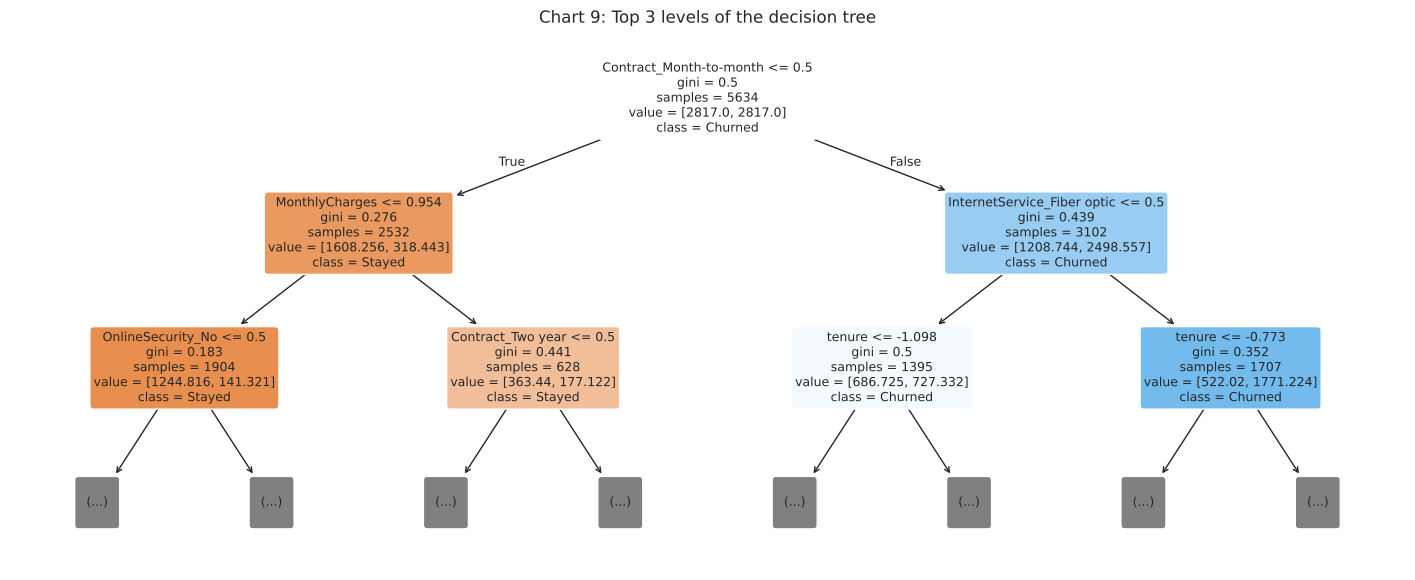

In [27]:
# Chart 9 - top of the decision tree:
tree_pipe = pipelines["Decision Tree (depth 5)"]
feature_names = tree_pipe.named_steps["preprocess"].get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]

plt.figure(figsize=(18, 7))
plot_tree(tree_pipe.named_steps["model"], max_depth=2, feature_names=feature_names,
          class_names=["Stayed", "Churned"], filled=True, rounded=True, fontsize=9)
plt.title("Chart 9: Top 3 levels of the decision tree")
plt.show()

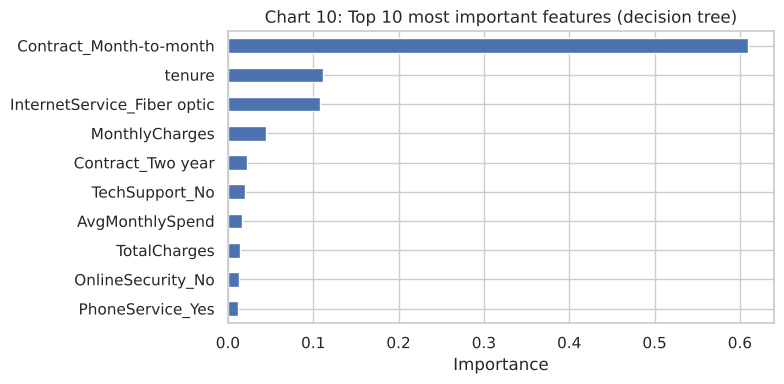

In [28]:
# Chart 10 - feature importance:
importances = pd.Series(tree_pipe.named_steps["model"].feature_importances_, index=feature_names)
top10 = importances.sort_values(ascending=False).head(10)
ax = top10.sort_values().plot(kind="barh", color="#4C72B0", figsize=(8, 4))
ax.set_title("Chart 10: Top 10 most important features (decision tree)")
ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 2.2 Comparison
| Model | CV F1 (AUC) | Test F1 (AUC) |
|---|---|---|
| Gaussian Naive Bayes | 0.597 (0.820) | 0.590 (0.806) |
| Bernoulli Naive Bayes | 0.610 (0.820) | 0.598 (0.806) |
| **Decision Tree (depth 5)** | **0.614 (0.829)** | **0.622 (0.832)** |
| Decision Tree (no limit) | 0.490 (0.653) | 0.497 (0.659) |

- **Best model: Decision Tree (depth 5)** — highest F1 and ROC-AUC in CV and on the test set; CV and test scores are close, so the result is stable.
- **Why NB is weaker:** it assumes features are independent, but TotalCharges ≈ tenure × MonthlyCharges (corr. 0.83) and AvgMonthlySpend repeats this, so NB double-counts evidence. It also can't model combinations like *month-to-month + fiber optic + short tenure → churn*, which the tree learns. Bernoulli NB beats Gaussian NB because most columns are 0/1 dummies, not bell-shaped.
- **Precision vs recall:** Gaussian NB catches the most churners (recall ≈ 0.83) but has the lowest precision (≈ 0.46); the tree is more balanced (precision ≈ 0.53, recall ≈ 0.76).
- **Overfitting:** the unlimited tree gets F1 0.996 on training data but only ≈ 0.49 on unseen data. Chart 6 shows validation F1 peaks around depth 3–5.
- **Most important features:** month-to-month contract (~60%), tenure, fiber-optic internet — same as the Part 1 EDA.
- The Part 1 logistic regression (CV F1 0.634) is still slightly better than a single tree → Part 3 will try ensembles and tuning.